# Descriptive stats for all columns

In [1]:
import matplotlib as plt
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

### Load the Data

In [2]:
RAW = "../data/data/raw"
df = pd.read_csv(f"{RAW}/diabetic_data.csv")
variables = pd.read_csv(f"{RAW}/variables.csv")

df.shape


C:\Users\piedu\AppData\Local\Temp\ipykernel_6688\810355052.py:2: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f"{RAW}/diabetic_data.csv")


(101766, 48)

#### View of Numerical data

In [3]:
df.describe()

,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


#### View of Categorical data

In [70]:
for col in df.select_dtypes("object"):
    if col in df.columns:
        print(col)

race
gender
age
weight
payer_code
medical_specialty
diag_1
diag_2
diag_3
max_glu_serum
A1Cresult
metformin
repaglinide
nateglinide
chlorpropamide
glimepiride
acetohexamide
glipizide
glyburide
tolbutamide
pioglitazone
rosiglitazone
acarbose
miglitol
troglitazone
tolazamide
examide
citoglipton
insulin
glyburide-metformin
glipizide-metformin
glimepiride-pioglitazone
metformin-rosiglitazone
metformin-pioglitazone
change
diabetesMed
readmitted


In [4]:
for col in df.select_dtypes("object"):
    print(df[col].value_counts(dropna=False))

race
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64
age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64
weight
NaN          98569
[75-100)      1336
[50-75)        897
[100-125)      625
[125-150)      145
[25-50)         97
[0-25)          48
[150-175)       35
[175-200)       11
>200             3
Name: count, dtype: int64
payer_code
NaN    40256
MC     32439
HM      6274
SP      5007
BC      4655
MD      3532
CP      2533
UN      2448
CM      1937
OG      1033
PO       592
DM       549
CH       146
WC       135
OT        95
MP        79
SI        55
FR         1
Name: count, dtype: int64
medical

Number of Categorical vs Numerical Columns

In [5]:
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(exclude="number").columns

print(f"Numeric columns: {len(num_cols)}")
print(f"Categorical columns: {len(cat_cols)}")
print(f"Total: {df.shape[1]}")

Numeric columns: 11
Categorical columns: 37
Total: 48


## Three-Class Readmitted Split

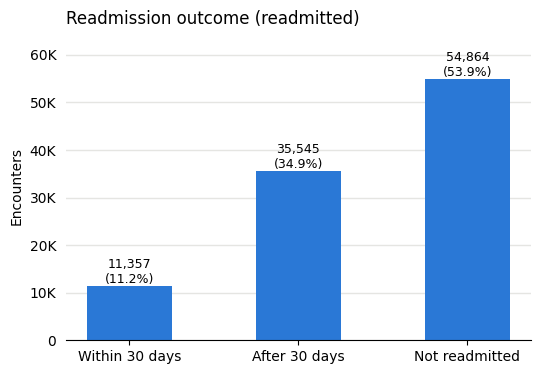

In [ ]:
# Count each class in a meaningful order (not sorted by size)
order = ["<30", ">30", "NO"]
counts = df["readmitted"].value_counts().reindex(order)
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Within 30 days", "After 30 days", "Not readmitted"], counts,
              width=0.5, color="#2a78d6")

# Count + percentage on top of each bar
for bar, n, p in zip(bars, counts, pct):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n:,}\n({p:.1f}%)",
            ha="center", va="bottom", fontsize=9)

ax.set_title("Readmission outcome (readmitted)", loc="left")
ax.set_ylabel("Encounters")
ax.yaxis.set_major_formatter(lambda y, _: f"{y/1000:.0f}K" if y else "0")
ax.set_ylim(0, counts.max() * 1.18)       
ax.grid(axis="y", color="#e5e5e2", linewidth=1)
ax.set_axisbelow(True)                   
ax.tick_params(left=False)

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

out = Path("../reports/figures")
out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "readmitted_split.png", dpi=200, bbox_inches="tight")
plt.show()


## Column Missing-ness Number

In [ ]:
missing_num = []

for col in df.columns:
    n_nan = df[col].isna().sum()
    if n_nan:
        missing_num.append([col, n_nan])
        print(f"{col}: {n_nan} NaN,({n_nan / len(df):.1%})")


race: 2273 NaN,(2.2%)
weight: 98569 NaN,(96.9%)
payer_code: 40256 NaN,(39.6%)
medical_specialty: 49949 NaN,(49.1%)
diag_1: 21 NaN,(0.0%)
diag_2: 358 NaN,(0.4%)
diag_3: 1423 NaN,(1.4%)
max_glu_serum: 96420 NaN,(94.7%)
A1Cresult: 84748 NaN,(83.3%)


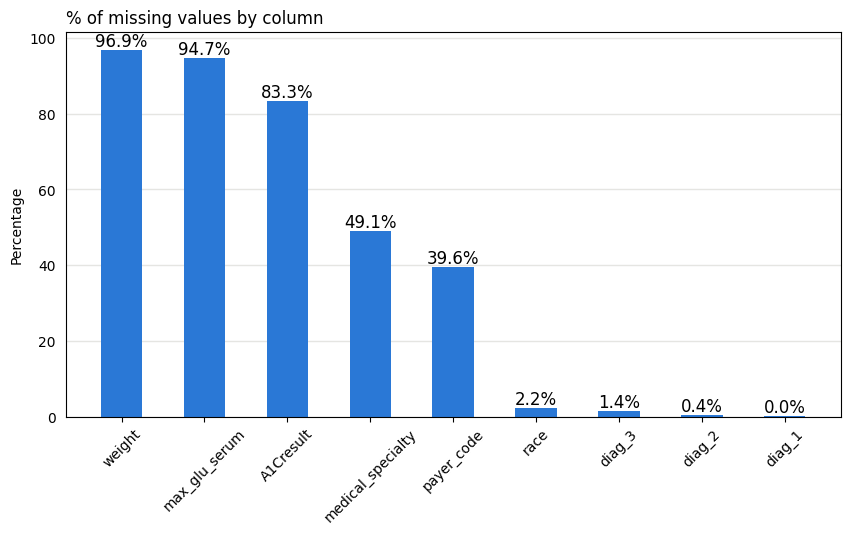

In [44]:
fig, ax = plt.subplots(figsize=(10, 5))

missing_num = sorted(missing_num, key=lambda x: x[1], reverse=True)

cols = [col for col, _ in missing_num]
pct = [num / len(df) * 100 for _, num in missing_num]
bars = ax.bar(cols, pct, width=0.5, color="#2a78d6")
ax.bar_label(bars, labels=[f"{p:.1f}%" for p in pct], fontsize=12)

ax.set_title("% of missing values by column", loc="left")
ax.set_ylabel("Percentage")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", color="#e5e5e2", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(left=False)

plt.show()


Columns over 50% missing values

In [62]:
def read_info(col):
    print(f"{df[col].dropna().sample(3)}")    
    print(f"{"-"*20}")

for col in cols:
    read_info(col)

49027     [50-75)
72958     [50-75)
39925    [75-100)
Name: weight, dtype: object
--------------------
19326    >300
3407     >300
65506    >300
Name: max_glu_serum, dtype: object
--------------------
59207    Norm
92263      >7
4145       >7
Name: A1Cresult, dtype: object
--------------------
41071    Emergency/Trauma
4419          Orthopedics
29750          Psychiatry
Name: medical_specialty, dtype: object
--------------------
59671    MC
56478    MC
33778    MC
Name: payer_code, dtype: object
--------------------
7770     AfricanAmerican
39825    AfricanAmerican
69438          Caucasian
Name: race, dtype: object
--------------------
14277       599
34837         8
714      250.02
Name: diag_3, dtype: object
--------------------
175        8
10673    413
91886    486
Name: diag_2, dtype: object
--------------------
17788    414
48124    428
21826    424
Name: diag_1, dtype: object
--------------------


## Target column plots against key Categorical Columns

In [89]:
drug_predictors = ["metformin",
"repaglinide",
"nateglinide",
"chlorpropamide",
"glimepiride",
"acetohexamide",
"glipizide",
"glyburide",
"tolbutamide",
"pioglitazone",
"rosiglitazone",
"acarbose",
"miglitol",
"troglitazone",
"tolazamide",
"examide",
"citoglipton",
"insulin",
"glyburide-metformin",
"glipizide-metformin",
"glimepiride-pioglitazone",
"metformin-rosiglitazone",
"metformin-pioglitazone",
]

y = [df[pred].sum() for pred in drug_predictors]

print(y)


# collapse rows into amount of non-No is present inside a drug 


# fig, args = plt.Subplots()

['...']


In [82]:
df["nateglinide"].unique()                     # just the distinct values


array(['No', 'Steady', 'Down', 'Up'], dtype=object)